# Sequential Pattern Analysis pada Dataset Online Retail

Notebook ini menerapkan Sequential Pattern Mining pada dataset Online Retail untuk menemukan pola pembelian berurutan antar waktu pada setiap pelanggan. Alur kerja mengikuti tugas Week 10: impor dataset, eksplorasi dan pembersihan, pembentukan sequence per pelanggan, penerapan PrefixSpan, evaluasi support dan confidence, serta penyusunan bahan laporan.

> Notebook ini disusun oleh Benedictus Ryu Gunawan (5054251001) untuk Tugas Week 10 - Sequential Pattern.

# Import Library

In [1]:
import time
import warnings
from bisect import bisect_right
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.ticker import FuncFormatter
from prefixspan import PrefixSpan

warnings.filterwarnings("ignore")

In [2]:
DATA_RELATIVE = Path("data") / "Online Retail.xlsx"


def resolve_root(start: Path) -> Path:
    for folder in [start, *start.parents]:
        if (folder / DATA_RELATIVE).is_file():
            return folder
    for candidate in sorted(start.glob("*/data/Online Retail.xlsx")):
        return candidate.parent.parent
    raise FileNotFoundError(f"{DATA_RELATIVE} not found from {start} or its parents")


@dataclass
class Config:
    ROOT_DIR: Path = resolve_root(Path.cwd())
    DATA_FILE: Path = ROOT_DIR / DATA_RELATIVE
    OUTPUT_DIR: Path = ROOT_DIR / "output"
    SEED: int = 42


cfg = Config()
cfg.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 180)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150})

print(f"Root directory: {cfg.ROOT_DIR}")
print(f"Data file: {cfg.DATA_FILE}")
print(f"Output directory: {cfg.OUTPUT_DIR}")
print(f"Seed: {cfg.SEED}")

Root directory: /home/ryz/data/collage/sem3/datmin/Repo/Week 10
Data file: /home/ryz/data/collage/sem3/datmin/Repo/Week 10/data/Online Retail.xlsx
Output directory: /home/ryz/data/collage/sem3/datmin/Repo/Week 10/output
Seed: 42


# Get Dataset

Dataset Online Retail diimpor dari file `data/Online Retail.xlsx`. Setiap baris merepresentasikan satu baris item pada invoice, sehingga satu invoice dapat terdiri dari banyak baris. Kolom yang menjadi kunci analisis adalah `CustomerID` untuk identitas pelanggan, `InvoiceDate` untuk urutan waktu, `InvoiceNo` untuk identitas transaksi, dan `Description` untuk nama produk.

In [3]:
t0 = time.time()
df_raw = pd.read_excel(cfg.DATA_FILE)
print(f"Waktu baca file: {time.time() - t0:.1f} detik")
print(f"Dataframe shape: {df_raw.shape}")
display(df_raw.head())

Waktu baca file: 21.1 detik
Dataframe shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
print("=== df_raw.info() ===")
df_raw.info()
print("\n=== Kolom ===")
print(df_raw.columns.tolist())
print("\n=== Missing values per kolom ===")
missing_table = df_raw.isna().sum().to_frame("n_missing")
missing_table["persen (%)"] = (missing_table["n_missing"] / len(df_raw) * 100).round(3)
display(missing_table)
print("\n=== Statistik deskriptif ===")
display(df_raw.describe(include=[np.number]).T.round(3))

=== df_raw.info() ===
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB

=== Kolom ===
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

=== Missing values per kolom ===


,n_missing,persen (%)
InvoiceNo,0,0.000
StockCode,0,0.000
Description,1454,0.268
Quantity,0,0.000
InvoiceDate,0,0.000
UnitPrice,0,0.000
CustomerID,135080,24.927
Country,0,0.000



=== Statistik deskriptif ===


,count,mean,std,min,25%,50%,75%,max
Quantity,541909.0,9.552,218.081,-80995.00,1.00,3.00,10.00,80995.0
UnitPrice,541909.0,4.611,96.760,-11062.06,1.25,2.08,4.13,38970.0
CustomerID,406829.0,15287.691,1713.600,12346.00,13953.00,15152.00,16791.00,18287.0


In [5]:
summary = pd.DataFrame({
    "tipe": df_raw.dtypes.astype(str),
    "non_null": df_raw.notna().sum(),
    "missing": df_raw.isna().sum(),
    "missing_pct": (df_raw.isna().mean() * 100).round(3),
    "n_unique": df_raw.nunique(),
})
display(summary)
print(f"Rentang tanggal: {df_raw.InvoiceDate.min()} sampai {df_raw.InvoiceDate.max()}")
print(f"Jumlah invoice: {df_raw.InvoiceNo.nunique():,}")
print(f"Jumlah pelanggan: {df_raw.CustomerID.nunique():,}")
print(f"Jumlah Description unik: {df_raw.Description.nunique():,}")
print(f"Jumlah negara: {df_raw.Country.nunique()} | share United Kingdom: {(df_raw.Country == 'United Kingdom').mean() * 100:.2f}%")

,tipe,non_null,missing,missing_pct,n_unique
InvoiceNo,object,541909,0,0.000,25900
StockCode,object,541909,0,0.000,4070
Description,object,540455,1454,0.268,4223
Quantity,int64,541909,0,0.000,722
InvoiceDate,datetime64[us],541909,0,0.000,23260
UnitPrice,float64,541909,0,0.000,1630
CustomerID,float64,406829,135080,24.927,4372
Country,str,541909,0,0.000,38


Rentang tanggal: 2010-12-01 08:26:00 sampai 2011-12-09 12:50:00
Jumlah invoice: 25,900
Jumlah pelanggan: 4,372
Jumlah Description unik: 4,223
Jumlah negara: 38 | share United Kingdom: 91.43%


## Struktur dan Kualitas Data

Dataset memiliki 541.909 baris, 25.900 invoice, dan 4.372 pelanggan dengan CustomerID. Kolom Description kosong pada 1.454 baris, sedangkan CustomerID kosong pada 135.080 baris (24,93%). Karena sequence dibentuk per pelanggan, baris tanpa CustomerID tidak dapat dipakai dan harus dihapus. Rentang transaksi adalah 1 Desember 2010 sampai 9 Desember 2011 dan 91,43% baris berasal dari United Kingdom.

Terdapat 4.223 nilai Description unik sebelum pembersihan. Setelah penyeragaman huruf, spasi, dan penghapusan layanan non-produk, tersisa 3.852 produk yang benar-benar dapat dianalisis sebagai item pembelian.

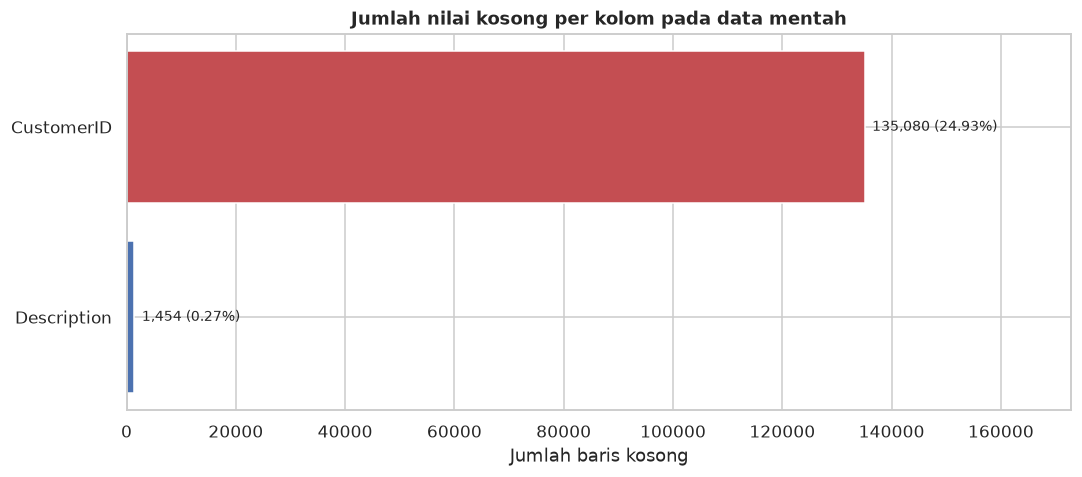

In [6]:
missing = df_raw.isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]
fig, ax = plt.subplots(figsize=(10, 4.5))
colors = ["#c44e52" if value > 10000 else "#4c72b0" for value in missing.values]
bars = ax.barh(missing.index[::-1], missing.values[::-1], color=colors[::-1], edgecolor="white")
ax.set_title("Jumlah nilai kosong per kolom pada data mentah", fontsize=12, fontweight="bold")
ax.set_xlabel("Jumlah baris kosong")
for bar, value in zip(bars, missing.values[::-1]):
    ax.text(value + max(missing) * 0.01, bar.get_y() + bar.get_height() / 2,
            f"{value:,} ({value / len(df_raw) * 100:.2f}%)", va="center", fontsize=9)
ax.set_xlim(0, max(missing) * 1.28)
plt.tight_layout()
plt.savefig(cfg.OUTPUT_DIR / "missing_values.png", dpi=150, bbox_inches="tight")
plt.show()

# Eksplorasi dan Pembersihan Data

Kolom yang relevan untuk sequential pattern mining adalah `CustomerID`, `InvoiceDate`, `InvoiceNo`, `Description`, dan `Quantity`. `StockCode` dipakai untuk menyaring baris non-produk. `UnitPrice` dan `Country` hanya dipakai sebagai konteks, bukan untuk pembentukan sequence.

Pembersihan dilakukan secara berurutan:

+ Menyeragamkan `Description` menjadi huruf kapital, menghapus spasi berlebih di awal, akhir, dan tengah teks, serta merapikan `InvoiceNo` dan `StockCode`.
+ Menghapus baris dengan `Description` kosong karena item tidak dapat diidentifikasi.
+ Menghapus invoice yang dibatalkan, yaitu `InvoiceNo` yang diawali huruf C.
+ Menghapus baris dengan `Quantity` negatif atau nol.
+ Menghapus baris dengan `CustomerID` kosong karena sequence disusun per pelanggan.
+ Menghapus baris non-produk seperti postage, bank charges, manual, dan gift voucher agar pola tidak berisi biaya layanan.

Langkah terakhir adalah tambahan agar pola yang ditemukan benar-benar mencerminkan produk ritel. Setiap tahap dicatat jumlah baris, invoice, dan pelanggannya.

In [7]:
df = df_raw.copy()
df["InvoiceNo"] = df["InvoiceNo"].astype(str).str.strip()
df["StockCode"] = df["StockCode"].astype(str).str.strip().str.upper()
df["Description"] = (
    df["Description"].astype("string").str.strip().str.upper().str.replace(r"\s+", " ", regex=True)
)

clean_steps = []


def record_step(label, data):
    clean_steps.append({
        "tahap": label,
        "baris": len(data),
        "invoice": data["InvoiceNo"].nunique(),
        "pelanggan": data["CustomerID"].nunique(),
    })


record_step("Data mentah", df)
n_desc_missing = int(df["Description"].isna().sum())
df = df.dropna(subset=["Description"])
record_step("Hapus Description kosong", df)

n_cancel_rows = int(df["InvoiceNo"].str.startswith("C").sum())
n_cancel_invoices = int(df.loc[df["InvoiceNo"].str.startswith("C"), "InvoiceNo"].nunique())
df = df[~df["InvoiceNo"].str.startswith("C")]
record_step("Hapus invoice batal (C)", df)

n_qty_nonpos = int((df["Quantity"] <= 0).sum())
df = df[df["Quantity"] > 0]
record_step("Hapus Quantity <= 0", df)

n_customer_missing = int(df["CustomerID"].isna().sum())
df = df.dropna(subset=["CustomerID"])
record_step("Hapus CustomerID kosong", df)

NON_PRODUCT_CODES = {
    "POST", "DOT", "M", "C2", "D", "S", "B", "BANK CHARGES",
    "AMAZONFEE", "CRUK", "PADS",
}
stock_code = df["StockCode"]
non_product_mask = stock_code.isin(NON_PRODUCT_CODES) | stock_code.str.startswith("GIFT_")
n_nonproduct = int(non_product_mask.sum())
df = df[~non_product_mask]
record_step("Hapus baris non-produk", df)

df["CustomerID"] = df["CustomerID"].astype(int)
clean_log = pd.DataFrame(clean_steps)
clean_log["baris_terhapus"] = clean_log["baris"].shift(1).fillna(clean_log["baris"]).astype(int) - clean_log["baris"]
clean_log["invoice_terhapus"] = clean_log["invoice"].shift(1).fillna(clean_log["invoice"]).astype(int) - clean_log["invoice"]
clean_log["pelanggan_hilang"] = clean_log["pelanggan"].shift(1).fillna(clean_log["pelanggan"]).astype(int) - clean_log["pelanggan"]
display(clean_log)
clean_log.to_csv(cfg.OUTPUT_DIR / "cleaning_summary.csv", index=False)

print(f"Description kosong: {n_desc_missing:,} baris")
print(f"Invoice batal (C): {n_cancel_rows:,} baris dari {n_cancel_invoices:,} invoice")
print(f"Quantity <= 0 setelah invoice batal dihapus: {n_qty_nonpos:,} baris")
print(f"CustomerID kosong: {n_customer_missing:,} baris")
print(f"Baris non-produk: {n_nonproduct:,} baris")
print(f"Data final: {len(df):,} baris | {df.InvoiceNo.nunique():,} invoice | {df.CustomerID.nunique():,} pelanggan | {df.Description.nunique():,} produk")

,tahap,baris,invoice,pelanggan,baris_terhapus,invoice_terhapus,pelanggan_hilang
0,Data mentah,541909,25900,4372,0,0,0
1,Hapus Description kosong,540455,24446,4372,1454,1454,0
2,Hapus invoice batal (C),531167,20610,4339,9288,3836,33
3,Hapus Quantity <= 0,530693,20136,4339,474,474,0
4,Hapus CustomerID kosong,397924,18536,4339,132769,1600,0
5,Hapus baris non-produk,396370,18405,4335,1554,131,4


Description kosong: 1,454 baris
Invoice batal (C): 9,288 baris dari 3,836 invoice
Quantity <= 0 setelah invoice batal dihapus: 474 baris
CustomerID kosong: 132,769 baris
Baris non-produk: 1,554 baris
Data final: 396,370 baris | 18,405 invoice | 4,335 pelanggan | 3,852 produk


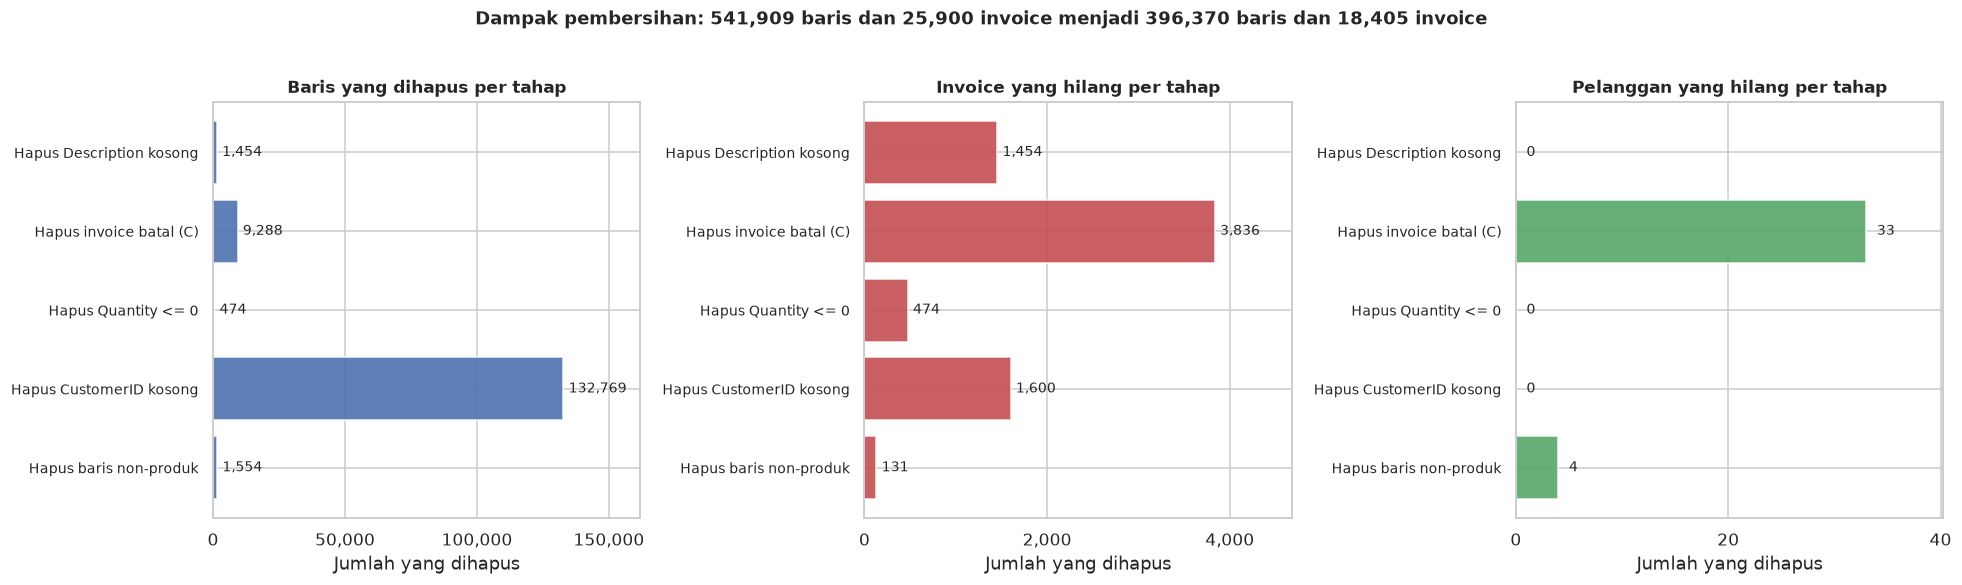

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
plot_steps = clean_log.iloc[1:].copy()
for ax, column, title, color in [
    (axes[0], "baris_terhapus", "Baris yang dihapus per tahap", "#4c72b0"),
    (axes[1], "invoice_terhapus", "Invoice yang hilang per tahap", "#c44e52"),
    (axes[2], "pelanggan_hilang", "Pelanggan yang hilang per tahap", "#55a868"),
]:
    positions = np.arange(len(plot_steps))
    bars = ax.barh(positions, plot_steps[column].values, color=color, alpha=0.9, edgecolor="white")
    ax.set_yticks(positions)
    ax.set_yticklabels(plot_steps["tahap"], fontsize=9)
    ax.invert_yaxis()
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel("Jumlah yang dihapus")
    for bar, value in zip(bars, plot_steps[column].values):
        ax.text(value + max(plot_steps[column].max() * 0.015, 1), bar.get_y() + bar.get_height() / 2,
                f"{value:,}", va="center", fontsize=9)
    ax.set_xlim(0, max(plot_steps[column].max() * 1.22, 1))
    ax.locator_params(axis="x", nbins=4)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, position: f"{value:,.0f}"))
plt.suptitle(f"Dampak pembersihan: {len(df_raw):,} baris dan {df_raw.InvoiceNo.nunique():,} invoice menjadi {len(df):,} baris dan {df.InvoiceNo.nunique():,} invoice",
             fontsize=12, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(cfg.OUTPUT_DIR / "cleaning_funnel.png", dpi=150, bbox_inches="tight")
plt.show()

Pembersihan menurunkan dataset dari 541.909 baris dan 25.900 invoice menjadi 396.370 baris dan 18.405 invoice, dengan 4.335 pelanggan yang memiliki sequence valid. Tahap yang menghapus baris terbanyak adalah penghapusan CustomerID kosong (132.769 baris), sedangkan tahap yang menghapus invoice terbanyak adalah pembatalan invoice (3.836 invoice). Sebanyak 33 pelanggan hanya memiliki invoice yang dibatalkan, dan 4 pelanggan hanya membeli layanan non-produk sehingga tidak memiliki produk yang dapat dianalisis.

Jumlah Description unik turun dari 4.223 menjadi 3.852 setelah penyeragaman teks dan penghapusan baris non-produk. Penurunan ini sebagian berasal dari penggabungan nama produk yang sebelumnya berbeda hanya karena spasi ganda, misalnya `LUNCH BAG  BLACK SKULL.` dan `LUNCH BAG BLACK SKULL.`.

## Distribusi Ukuran Keranjang

Ukuran keranjang dihitung dari jumlah Description unik per invoice. Distribusinya miring ke kanan: median 15 produk, rata-rata 20,98 produk, kuartil ketiga 27 produk, dan nilai maksimum 540 produk. Sebanyak 90% invoice berisi paling banyak 46 produk. Invoice besar tetap dipertahankan karena merepresentasikan pembelian grosir atau pesanan besar yang sah.

,count,mean,std,min,25%,50%,75%,max
unique_items,18405.0,20.98,23.8,1.0,7.0,15.0,27.0,540.0


,unique_items
0.50,15.00
0.75,27.00
0.90,46.00
0.95,62.00
0.99,103.96


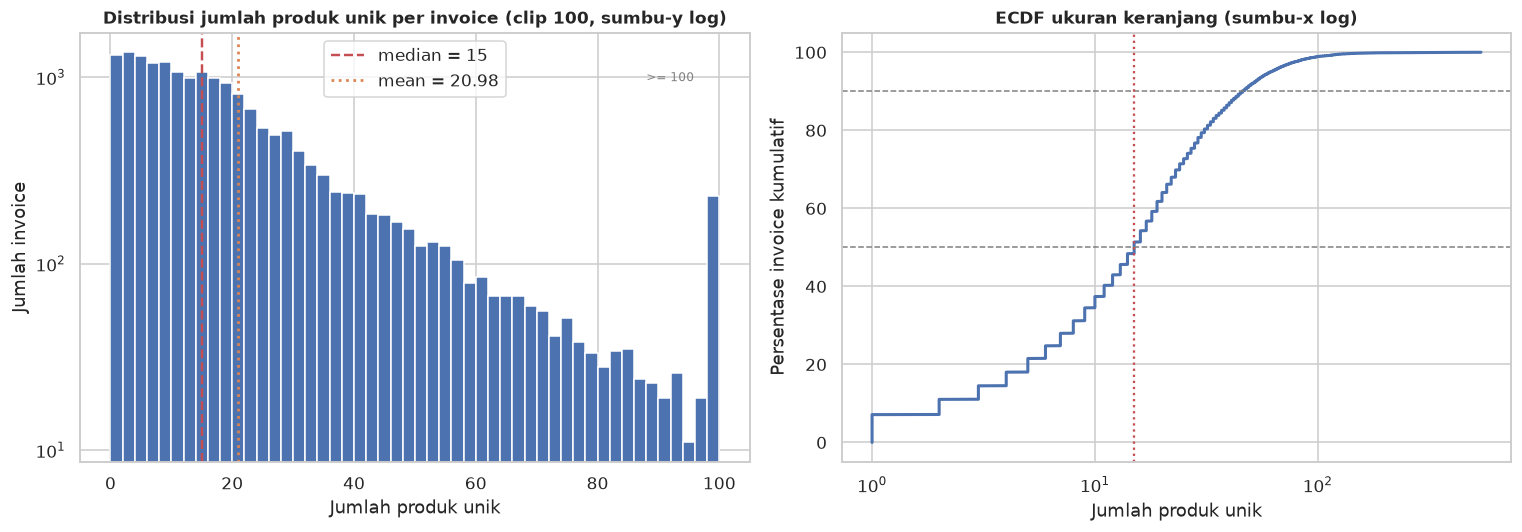

In [9]:
invoice_sizes = df.groupby("InvoiceNo")["Description"].nunique()
display(invoice_sizes.describe().to_frame("unique_items").T.round(2))
display(invoice_sizes.quantile([0.5, 0.75, 0.9, 0.95, 0.99]).to_frame("unique_items").round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(invoice_sizes.clip(upper=100), bins=range(0, 102, 2), color="#4c72b0", edgecolor="white")
axes[0].set_yscale("log")
axes[0].axvline(invoice_sizes.median(), color="#c44e52", linestyle="--", linewidth=1.6, label=f"median = {invoice_sizes.median():.0f}")
axes[0].axvline(invoice_sizes.mean(), color="#dd8452", linestyle=":", linewidth=1.8, label=f"mean = {invoice_sizes.mean():.2f}")
axes[0].set_title("Distribusi jumlah produk unik per invoice (clip 100, sumbu-y log)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Jumlah produk unik")
axes[0].set_ylabel("Jumlah invoice")
axes[0].set_xticks(range(0, 101, 20))
axes[0].legend()
axes[0].text(88, axes[0].get_ylim()[1] * 0.55, ">= 100", fontsize=8, color="gray")
sorted_sizes = np.sort(invoice_sizes.values)
ecdf = np.arange(1, len(sorted_sizes) + 1) / len(sorted_sizes) * 100
axes[1].plot(sorted_sizes, ecdf, color="#4c72b0", linewidth=2)
axes[1].set_xscale("log")
axes[1].axhline(50, color="gray", linestyle="--", linewidth=1)
axes[1].axhline(90, color="gray", linestyle="--", linewidth=1)
axes[1].axvline(invoice_sizes.median(), color="#c44e52", linestyle=":", linewidth=1.5)
axes[1].set_title("ECDF ukuran keranjang (sumbu-x log)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Jumlah produk unik")
axes[1].set_ylabel("Persentase invoice kumulatif")
plt.tight_layout()
plt.savefig(cfg.OUTPUT_DIR / "invoice_size_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## Produk Terpopuler

Produk dengan pelanggan terbanyak adalah REGENCY CAKESTAND 3 TIER (881 pelanggan, 20,32%), WHITE HANGING HEART T-LIGHT HOLDER (856 pelanggan, 19,75%), dan PARTY BUNTING (708 pelanggan, 16,33%). Sepuluh produk teratas hanya mencakup 2,55% dari seluruh pasangan pelanggan-produk, dan dibutuhkan 1.338 produk untuk mencakup 80% pasangan. Distribusi long tail ini membuat pencarian pola pada seluruh katalog menjadi sangat mahal, sehingga kosakata produk perlu dibatasi secara terkontrol.

,jumlah_pelanggan,support_pelanggan_pct,jumlah_invoice
Description,,,
REGENCY CAKESTAND 3 TIER,881,20.32,1704
WHITE HANGING HEART T-LIGHT HOLDER,856,19.75,1971
PARTY BUNTING,708,16.33,1380
ASSORTED COLOUR BIRD ORNAMENT,678,15.64,1375
SET OF 3 CAKE TINS PANTRY DESIGN,640,14.76,1146
JUMBO BAG RED RETROSPOT,635,14.65,1600
PACK OF 72 RETROSPOT CAKE CASES,635,14.65,1029
PAPER CHAIN KIT 50'S CHRISTMAS,613,14.14,980
NATURAL SLATE HEART CHALKBOARD,587,13.54,967


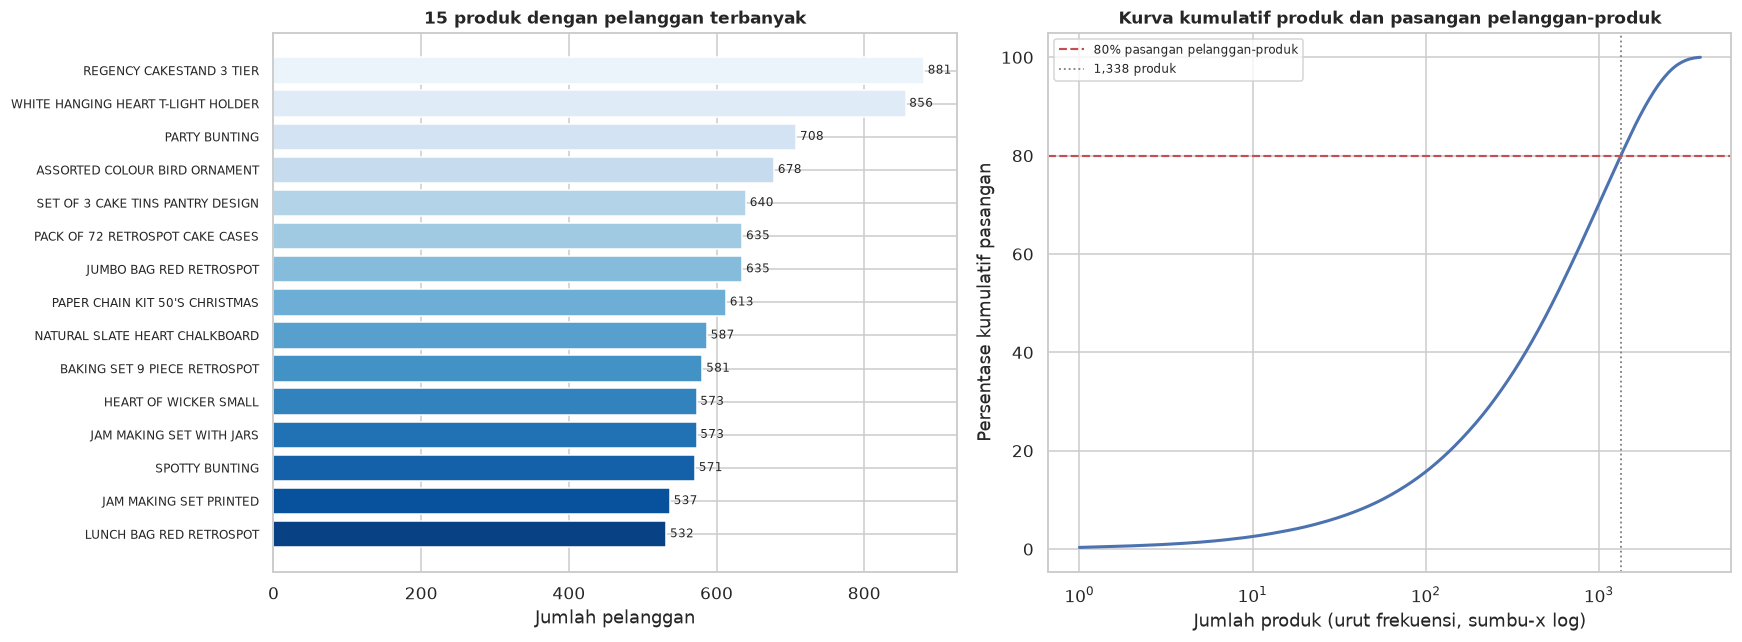

Top 10 produk mencakup 2.55% pasangan pelanggan-produk
Produk yang dibutuhkan untuk 80% pasangan: 1,338
Jumlah produk setelah pembersihan: 3,852


In [10]:
item_cust = df.groupby("Description")["CustomerID"].nunique().sort_values(ascending=False)
item_invoice = df.groupby("Description")["InvoiceNo"].nunique().sort_values(ascending=False)
top_products = pd.DataFrame({
    "jumlah_pelanggan": item_cust.head(15),
    "support_pelanggan_pct": (item_cust.head(15) / df.CustomerID.nunique() * 100).round(2),
    "jumlah_invoice": item_invoice.reindex(item_cust.head(15).index),
})
display(top_products)
top_products.to_csv(cfg.OUTPUT_DIR / "top_products.csv")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
top15 = item_cust.head(15).sort_values()
axes[0].barh(top15.index, top15.values, color=sns.color_palette("Blues_r", len(top15)), edgecolor="white")
axes[0].set_title("15 produk dengan pelanggan terbanyak", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Jumlah pelanggan")
axes[0].tick_params(axis="y", labelsize=8)
for index, value in enumerate(top15.values):
    axes[0].text(value + 5, index, f"{value:,}", va="center", fontsize=8)
cum = item_cust.cumsum() / item_cust.sum() * 100
products_80 = int((cum < 80).sum() + 1)
axes[1].plot(np.arange(1, len(item_cust) + 1), cum.values, color="#4c72b0", linewidth=2)
axes[1].set_xscale("log")
axes[1].axhline(80, color="#c44e52", linestyle="--", linewidth=1.4, label="80% pasangan pelanggan-produk")
axes[1].axvline(products_80, color="gray", linestyle=":", linewidth=1.2, label=f"{products_80:,} produk")
axes[1].set_title("Kurva kumulatif produk dan pasangan pelanggan-produk", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Jumlah produk (urut frekuensi, sumbu-x log)")
axes[1].set_ylabel("Persentase kumulatif pasangan")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(cfg.OUTPUT_DIR / "top_products.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Top 10 produk mencakup {item_cust.head(10).sum() / item_cust.sum() * 100:.2f}% pasangan pelanggan-produk")
print(f"Produk yang dibutuhkan untuk 80% pasangan: {products_80:,}")
print(f"Jumlah produk setelah pembersihan: {len(item_cust):,}")

## Panjang Sequence per Pelanggan

Sequence per pelanggan berisi daftar invoice yang diurutkan berdasarkan waktu. Sebanyak 50% pelanggan hanya memiliki 2 invoice atau kurang, sedangkan rata-rata jumlah invoice per pelanggan adalah 4,25 dan nilai maksimum 206 invoice. Rata-rata satu pelanggan memiliki 89,08 item unik, dengan median 40 item. Distribusi ini menunjukkan bahwa sebagian besar pelanggan adalah pembeli musiman, tetapi ada kelompok kecil pelanggan setia dengan ratusan transaksi.

,count,mean,std,min,25%,50%,75%,max
n_invoice,4335.0,4.25,7.64,1.0,1.0,2.0,5.0,206.0


,count,mean,std,min,25%,50%,75%,max
n_item,4335.0,89.08,221.36,1.0,17.0,40.0,97.0,7466.0


Jumlah pelanggan: 4,335
Jumlah invoice: 18,405
Rata-rata item per invoice: 20.98


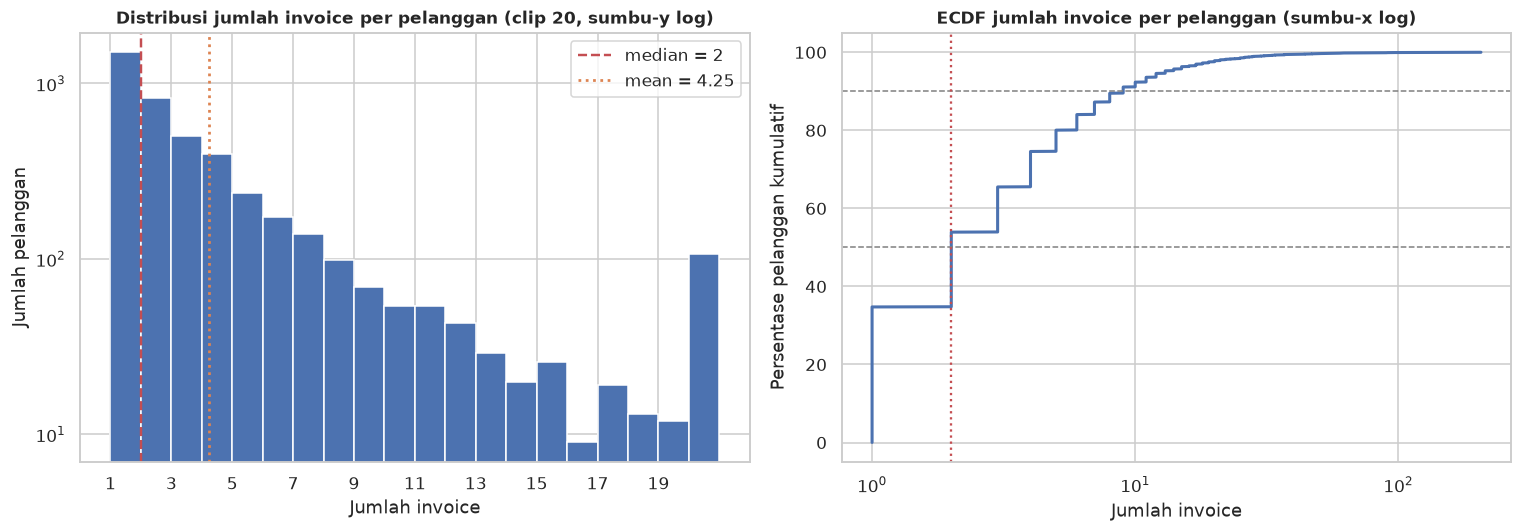

In [11]:
df_sorted = df.sort_values(["CustomerID", "InvoiceDate", "InvoiceNo"])
invoice_items = (
    df_sorted.groupby(["CustomerID", "InvoiceNo"], sort=False)["Description"]
    .apply(lambda values: tuple(sorted(set(values))))
    .reset_index()
)
customer_sequences = invoice_items.groupby("CustomerID", sort=False)["Description"].apply(list).reset_index()
customer_sequences.columns = ["CustomerID", "itemsets"]

sequence_lengths = customer_sequences["itemsets"].apply(len)
sequence_items = customer_sequences["itemsets"].apply(lambda sets: sum(len(itemset) for itemset in sets))
display(sequence_lengths.describe().to_frame("n_invoice").T.round(2))
display(sequence_items.describe().to_frame("n_item").T.round(2))
print(f"Jumlah pelanggan: {len(customer_sequences):,}")
print(f"Jumlah invoice: {len(invoice_items):,}")
print(f"Rata-rata item per invoice: {np.mean([len(itemset) for itemsets in customer_sequences['itemsets'] for itemset in itemsets]):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(sequence_lengths.clip(upper=20), bins=range(1, 22), color="#4c72b0", edgecolor="white")
axes[0].set_yscale("log")
axes[0].axvline(sequence_lengths.median(), color="#c44e52", linestyle="--", linewidth=1.6, label=f"median = {sequence_lengths.median():.0f}")
axes[0].axvline(sequence_lengths.mean(), color="#dd8452", linestyle=":", linewidth=1.8, label=f"mean = {sequence_lengths.mean():.2f}")
axes[0].set_title("Distribusi jumlah invoice per pelanggan (clip 20, sumbu-y log)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Jumlah invoice")
axes[0].set_ylabel("Jumlah pelanggan")
axes[0].set_xticks(range(1, 21, 2))
axes[0].legend()
sorted_lengths = np.sort(sequence_lengths.values)
ecdf = np.arange(1, len(sorted_lengths) + 1) / len(sorted_lengths) * 100
axes[1].plot(sorted_lengths, ecdf, color="#4c72b0", linewidth=2)
axes[1].set_xscale("log")
axes[1].axhline(50, color="gray", linestyle="--", linewidth=1)
axes[1].axhline(90, color="gray", linestyle="--", linewidth=1)
axes[1].axvline(sequence_lengths.median(), color="#c44e52", linestyle=":", linewidth=1.5)
axes[1].set_title("ECDF jumlah invoice per pelanggan (sumbu-x log)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Jumlah invoice")
axes[1].set_ylabel("Persentase pelanggan kumulatif")
plt.tight_layout()
plt.savefig(cfg.OUTPUT_DIR / "sequence_length_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

# Persiapan Data untuk Sequential Pattern Mining

Data baris demi baris diubah menjadi sequence pembelian per pelanggan. Untuk setiap pasangan `CustomerID` dan `InvoiceNo`, daftar Description diubah menjadi himpunan unik agar produk yang sama tidak dihitung dua kali dalam satu invoice. Setiap itemset kemudian diurutkan secara kanonik, dan itemset antar invoice diurutkan berdasarkan `InvoiceDate`. Hasilnya adalah satu sequence per pelanggan yang berbentuk daftar itemset.

Contoh sequence lima pelanggan pertama ditampilkan pada tabel berikut. Kolom `contoh` hanya menampilkan dua itemset pertama agar tabel tetap ringkas. Seluruh sequence disimpan pada file `output/customer_sequences.csv`.

In [12]:
def short_list(items, max_len=95):
    text = " | ".join(items)
    return text if len(text) <= max_len else text[: max_len - 3] + "..."


preview = customer_sequences.head(6).copy()
preview["n_invoice"] = preview["itemsets"].apply(len)
preview["n_item"] = preview["itemsets"].apply(lambda sets: sum(len(itemset) for itemset in sets))
preview["contoh"] = preview["itemsets"].apply(lambda sets: short_list([", ".join(itemset) for itemset in sets[:2]]))
display(preview[["CustomerID", "n_invoice", "n_item", "contoh"]])

sequence_export = customer_sequences.copy()
sequence_export["n_invoice"] = sequence_export["itemsets"].apply(len)
sequence_export["n_item"] = sequence_export["itemsets"].apply(lambda sets: sum(len(itemset) for itemset in sets))
sequence_export["sequence"] = sequence_export["itemsets"].apply(
    lambda sets: " -> ".join(" | ".join(itemset) for itemset in sets)
)
sequence_export[["CustomerID", "n_invoice", "n_item", "sequence"]].to_csv(
    cfg.OUTPUT_DIR / "customer_sequences.csv", index=False
)

print(f"Sequence tersimpan: {len(sequence_export):,} pelanggan")
print(f"Rata-rata invoice per pelanggan: {sequence_lengths.mean():.2f}")
print(f"Rata-rata item per pelanggan: {sequence_items.mean():.2f}")

,CustomerID,n_invoice,n_item,contoh
0,12346,1,1,MEDIUM CERAMIC TOP STORAGE JAR
1,12347,7,182,"3D DOG PICTURE PLAYING CARDS, AIRLINE BAG VINTAGE JET SET BROWN, ALARM CLOCK BAKELIKE CHOCOL..."
2,12348,4,23,"60 CAKE CASES DOLLY GIRL DESIGN, 60 CAKE CASES VINTAGE CHRISTMAS, 60 TEATIME FAIRY CAKE CASE..."
3,12349,1,72,"16 PIECE CUTLERY SET PANTRY DESIGN, 20 DOLLY PEGS RETROSPOT, BLACK/BLUE POLKADOT UMBRELLA, B..."
4,12350,1,16,"4 TRADITIONAL SPINNING TOPS, BATHROOM METAL SIGN, BLUE POLKADOT LUGGAGE TAG, BLUE POLKADOT P..."
5,12352,7,77,"BATH BUILDING BLOCK WORD, BIG DOUGHNUT FRIDGE MAGNETS, CAT BOWL VINTAGE CREAM, CERAMIC STRAW..."


Sequence tersimpan: 4,335 pelanggan
Rata-rata invoice per pelanggan: 4.25
Rata-rata item per pelanggan: 89.08


## Pemilihan Kosakata Produk

PrefixSpan bekerja paling efisien ketika jumlah item tidak terlalu besar. Secara teori, produk dengan support di bawah minimum support tidak mungkin muncul pada pola frequent, sehingga produk tersebut dapat dipangkas tanpa kehilangan pola. Tabel berikut menunjukkan jumlah produk yang lolos filter pada beberapa nilai minimum support. Pada support 1% masih ada 1.783 produk dan proses pencarian menjadi sangat mahal, sedangkan pada support 3% tersisa 662 produk yang masih mencakup produk-produk utama.

Nilai 3% dipilih sebagai titik final karena memberi keseimbangan antara cakupan produk dan biaya komputasi. Produk long tail tetap tidak dibuang dari dataset, hanya tidak dilibatkan dalam pencarian pola pada threshold tersebut.

,min_support_pct,min_support_count,jumlah_produk
0,1,43,1783
1,2,86,1054
2,3,130,662
3,4,173,421
4,5,216,266


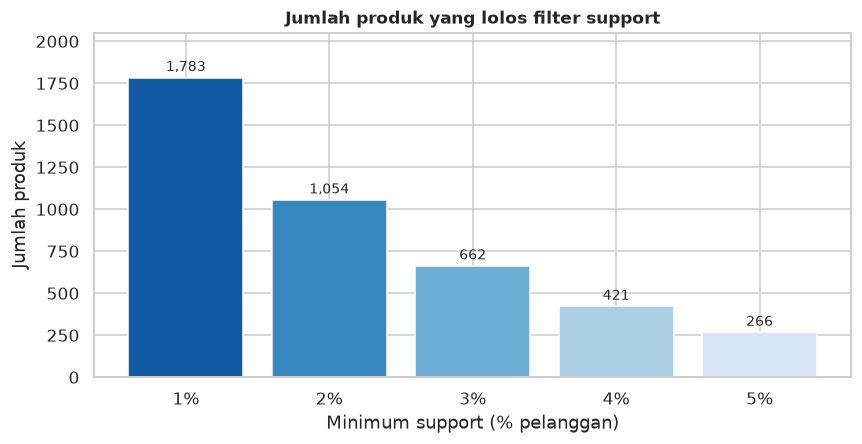

In [13]:
n_customers = len(customer_sequences)
vocabulary_table = pd.DataFrame({"min_support_pct": [1, 2, 3, 4, 5]})
vocabulary_table["min_support_count"] = (vocabulary_table["min_support_pct"] / 100 * n_customers).astype(int)
vocabulary_table["jumlah_produk"] = [
    int((item_cust >= count).sum()) for count in vocabulary_table["min_support_count"]
]
display(vocabulary_table)

fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.bar(
    vocabulary_table["min_support_pct"].astype(str) + "%",
    vocabulary_table["jumlah_produk"],
    color=sns.color_palette("Blues_r", len(vocabulary_table)),
    edgecolor="white",
)
ax.set_title("Jumlah produk yang lolos filter support", fontsize=11, fontweight="bold")
ax.set_xlabel("Minimum support (% pelanggan)")
ax.set_ylabel("Jumlah produk")
for bar, value in zip(bars, vocabulary_table["jumlah_produk"]):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 40, f"{value:,}", ha="center", fontsize=9)
ax.set_ylim(0, vocabulary_table["jumlah_produk"].max() * 1.15)
plt.tight_layout()
plt.savefig(cfg.OUTPUT_DIR / "vocabulary_support.png", dpi=150, bbox_inches="tight")
plt.show()

# Penerapan Algoritma PrefixSpan

PrefixSpan membangun pola dengan cara memproyeksikan database sequence pada setiap prefix yang frequent. Berbeda dari Apriori yang membangkitkan kandidat, PrefixSpan hanya menumbuhkan prefix yang benar-benar didukung data sehingga lebih efisien pada sequence yang panjang. Implementasi memakai pustaka `prefixspan` dengan `maxlen=3`, sehingga pola yang dicari terdiri dari satu sampai tiga langkah.

Setiap invoice adalah itemset, tetapi PrefixSpan bekerja pada urutan item. Karena itu itemset diekspansi menjadi daftar item unik dengan urutan kanonik, lalu seluruh item pelanggan digabung secara kronologis. Support setiap pola yang ditemukan PrefixSpan diverifikasi ulang pada level itemset dengan aturan ketat: item pertama harus muncul pada invoice yang lebih awal daripada item berikutnya. Verifikasi ini membuang pola yang hanya muncul karena dua produk kebetulan berada pada invoice yang sama, sehingga pola yang dilaporkan benar-benar berurutan antar waktu.

## Parameter Awal dan Penyesuaian

Titik awal tugas adalah minimum support 0,01 atau 1% dari jumlah pelanggan, yaitu 43 pelanggan. Pada nilai ini terdapat 1.783 produk yang lolos filter dan jumlah pola membengkak, sehingga proses pencarian menjadi sangat mahal. Support kemudian dinaikkan bertahap dan diuji pada nilai 2% sampai 5%. Tabel dan grafik berikut menunjukkan jumlah pola yang bertahan setelah verifikasi itemset.

Support 2% masih menghasilkan 2.064 pola berurutan, terlalu banyak untuk ditinjau dan diinterpretasikan. Support 4% hanya menyisakan 64 pola berurutan, sedangkan support 5% hanya menyisakan 10 pola sehingga banyak pola penting hilang. Support 3% dipilih karena menghasilkan 302 pola berurutan yang masih cukup kaya untuk dianalisis, dengan 662 produk sebagai kosakata.

In [14]:
def build_positions(sequences, vocabulary):
    positions = []
    restricted = []
    for itemsets in sequences:
        filtered = [set(item for item in itemset if item in vocabulary) for itemset in itemsets]
        restricted.append(filtered)
        item_positions = {}
        for index, itemset in enumerate(filtered):
            for item in itemset:
                item_positions.setdefault(item, []).append(index)
        positions.append(item_positions)
    return restricted, positions


def strict_support(pattern, positions):
    count = 0
    for customer_positions in positions:
        current = -1
        for item in pattern:
            item_positions = customer_positions.get(item)
            if not item_positions:
                break
            index = bisect_right(item_positions, current)
            if index == len(item_positions):
                break
            current = item_positions[index]
        else:
            count += 1
    return count


def mine_patterns(sequences, min_support):
    vocabulary = set(item_cust[item_cust >= min_support].index)
    restricted, positions = build_positions(sequences, vocabulary)
    flat = [[item for itemset in itemsets for item in sorted(itemset)] for itemsets in restricted]
    flat = [sequence for sequence in flat if sequence]
    miner = PrefixSpan(flat)
    miner.maxlen = 3
    frequent = miner.frequent(min_support)
    patterns = []
    for _, pattern in frequent:
        support = strict_support(pattern, positions)
        if support >= min_support:
            patterns.append((pattern, support))
    return vocabulary, patterns

,min_support,min_support_count,vocabulary,pola_total,pola_berurutan,waktu_detik
0,0.02,86,1054,3118,2064,22.24
1,0.03,130,662,964,302,7.12
2,0.04,173,421,485,64,3.12
3,0.05,216,266,276,10,1.47


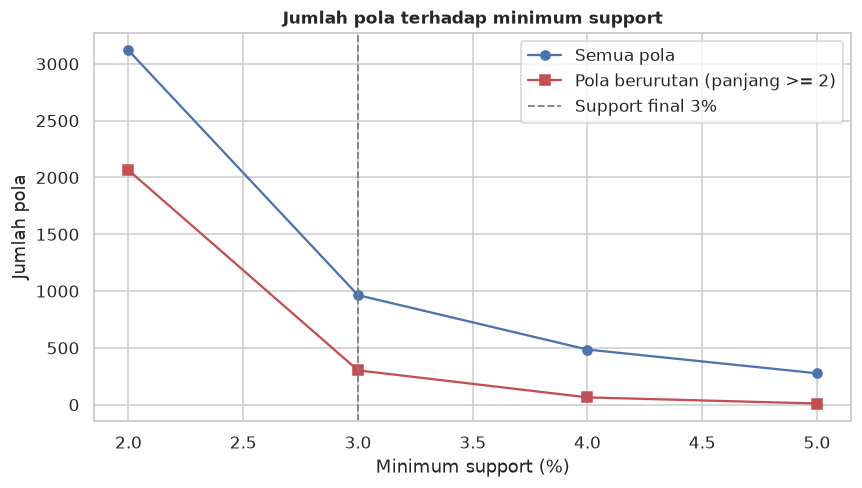

In [15]:
sensitivity_rows = []
for fraction in [0.02, 0.03, 0.04, 0.05]:
    min_support = int(n_customers * fraction)
    started = time.time()
    vocabulary, patterns = mine_patterns(customer_sequences["itemsets"].tolist(), min_support)
    sensitivity_rows.append({
        "min_support": fraction,
        "min_support_count": min_support,
        "vocabulary": len(vocabulary),
        "pola_total": len(patterns),
        "pola_berurutan": sum(1 for pattern, support in patterns if len(pattern) >= 2),
        "waktu_detik": round(time.time() - started, 2),
    })
sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity)
sensitivity.to_csv(cfg.OUTPUT_DIR / "parameter_sensitivity.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(sensitivity["min_support"] * 100, sensitivity["pola_total"], marker="o", color="#4c72b0", label="Semua pola")
ax.plot(sensitivity["min_support"] * 100, sensitivity["pola_berurutan"], marker="s", color="#c44e52", label="Pola berurutan (panjang >= 2)")
ax.axvline(3, color="gray", linestyle="--", linewidth=1.2, label="Support final 3%")
ax.set_title("Jumlah pola terhadap minimum support", fontsize=11, fontweight="bold")
ax.set_xlabel("Minimum support (%)")
ax.set_ylabel("Jumlah pola")
ax.legend()
plt.tight_layout()
plt.savefig(cfg.OUTPUT_DIR / "parameter_sensitivity.png", dpi=150, bbox_inches="tight")
plt.show()

## Model Final

Kombinasi final adalah minimum support 3% (130 pelanggan), kosakata 662 produk, dan panjang pola maksimum tiga langkah. Hasilnya adalah 964 pola, terdiri dari 662 pola satu langkah (produk frequent), 291 pola dua langkah, dan 11 pola tiga langkah. Pola satu langkah dipakai sebagai konteks produk populer; analisis pola berurutan difokuskan pada 302 pola dengan panjang minimal dua.

Confidence dihitung sebagai support pola dibagi support prefix-nya. Untuk pola dua langkah A -> B, confidence adalah peluang pelanggan membeli B pada invoice berikutnya jika sebelumnya membeli A. Untuk pola tiga langkah A -> B -> C, confidence adalah peluang melanjutkan ke C jika sudah membeli A lalu B. Nilai ini berbeda dari confidence association rule karena arah waktunya diperhitungkan.

In [16]:
MIN_SUPPORT = 0.03
min_support = int(n_customers * MIN_SUPPORT)
vocabulary, strict_patterns = mine_patterns(customer_sequences["itemsets"].tolist(), min_support)
support_map = {tuple(pattern): support for pattern, support in strict_patterns}

pattern_records = []
for pattern, support in strict_patterns:
    prefix = tuple(pattern[:-1])
    confidence = support / support_map[prefix] if len(pattern) > 1 else np.nan
    pattern_records.append({
        "pola": " -> ".join(pattern),
        "panjang": len(pattern),
        "tipe": "Satu item" if len(pattern) == 1 else ("Pembelian ulang" if len(set(pattern)) < len(pattern) else "Lintas produk"),
        "support": support,
        "support_pct": round(support / n_customers * 100, 3),
        "confidence": confidence,
    })
patterns_df = pd.DataFrame(pattern_records).sort_values(["support", "confidence"], ascending=False).reset_index(drop=True)
display(patterns_df.head(15))
patterns_df.to_csv(cfg.OUTPUT_DIR / "patterns_final.csv", index=False)

print(f"Minimum support: {MIN_SUPPORT:.0%} = {min_support} pelanggan")
print(f"Kosakata produk: {len(vocabulary):,}")
print(f"Jumlah pola total: {len(patterns_df):,}")
print(patterns_df["panjang"].value_counts().sort_index().to_string())
print(patterns_df["tipe"].value_counts().to_string())

,pola,panjang,tipe,support,support_pct,confidence
0,REGENCY CAKESTAND 3 TIER,1,Satu item,881,20.323,NaN
1,WHITE HANGING HEART T-LIGHT HOLDER,1,Satu item,856,19.746,NaN
2,PARTY BUNTING,1,Satu item,708,16.332,NaN
3,ASSORTED COLOUR BIRD ORNAMENT,1,Satu item,678,15.640,NaN
4,SET OF 3 CAKE TINS PANTRY DESIGN,1,Satu item,640,14.764,NaN
5,PACK OF 72 RETROSPOT CAKE CASES,1,Satu item,635,14.648,NaN
6,JUMBO BAG RED RETROSPOT,1,Satu item,635,14.648,NaN
7,PAPER CHAIN KIT 50'S CHRISTMAS,1,Satu item,613,14.141,NaN
8,NATURAL SLATE HEART CHALKBOARD,1,Satu item,587,13.541,NaN
9,BAKING SET 9 PIECE RETROSPOT,1,Satu item,581,13.403,NaN


Minimum support: 3% = 130 pelanggan
Kosakata produk: 662
Jumlah pola total: 964
panjang
1    662
2    291
3     11
tipe
Satu item          662
Lintas produk      231
Pembelian ulang     71


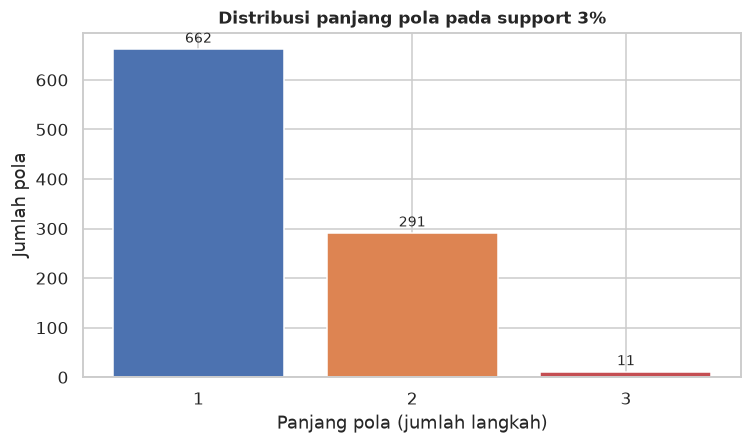

In [17]:
fig, ax = plt.subplots(figsize=(7, 4.2))
length_counts = patterns_df["panjang"].value_counts().sort_index()
bars = ax.bar(length_counts.index.astype(str), length_counts.values, color=["#4c72b0", "#dd8452", "#c44e52"], edgecolor="white")
ax.set_title("Distribusi panjang pola pada support 3%", fontsize=11, fontweight="bold")
ax.set_xlabel("Panjang pola (jumlah langkah)")
ax.set_ylabel("Jumlah pola")
for bar, value in zip(bars, length_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + max(length_counts) * 0.02, f"{value:,}", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig(cfg.OUTPUT_DIR / "pattern_length_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

# Evaluasi Pola Berurutan

Support mengukur proporsi pelanggan yang memiliki pola tersebut pada sequence-nya. Confidence mengukur proporsi pelanggan yang melanjutkan prefix pola ke langkah berikutnya. Karena pola dibatasi maksimum tiga langkah, pola dengan panjang dua adalah pola berurutan utama, sedangkan pola panjang tiga menunjukkan kelanjutan yang lebih spesifik.

Tabel berikut menampilkan sepuluh pola berurutan dengan support tertinggi. Pola dengan item berulang, misalnya A -> A, termasuk kategori pembelian ulang dan muncul paling sering karena produk populer cenderung dibeli lagi pada invoice berikutnya. Pola lintas produk, yaitu A -> B dengan A dan B berbeda, lebih relevan untuk rekomendasi cross-sell.

In [18]:
sequential = patterns_df[patterns_df["panjang"] >= 2].copy()
distinct = sequential[sequential["tipe"] == "Lintas produk"].copy()
display(sequential.head(10)[["pola", "tipe", "support", "support_pct", "confidence"]].round(3))
display(distinct.head(10)[["pola", "support", "support_pct", "confidence"]].round(3))

top_patterns = sequential.head(20).copy()
top_distinct = distinct.head(20).copy()
top_patterns.to_csv(cfg.OUTPUT_DIR / "top_patterns.csv", index=False)
top_distinct.to_csv(cfg.OUTPUT_DIR / "top_distinct_patterns.csv", index=False)

print(f"Pola berurutan: {len(sequential):,}")
print(f"Pola lintas produk: {len(distinct):,}")
print(f"Pola pembelian ulang: {len(sequential) - len(distinct):,}")

,pola,tipe,support,support_pct,confidence
38,WHITE HANGING HEART T-LIGHT HOLDER -> WHITE HANGING HEART T-LIGHT HOLDER,Pembelian ulang,405,9.343,0.473
89,REGENCY CAKESTAND 3 TIER -> REGENCY CAKESTAND 3 TIER,Pembelian ulang,330,7.612,0.375
110,JUMBO BAG RED RETROSPOT -> JUMBO BAG RED RETROSPOT,Pembelian ulang,312,7.197,0.491
133,ASSORTED COLOUR BIRD ORNAMENT -> ASSORTED COLOUR BIRD ORNAMENT,Pembelian ulang,291,6.713,0.429
151,PARTY BUNTING -> PARTY BUNTING,Pembelian ulang,280,6.459,0.395
157,LUNCH BAG RED RETROSPOT -> LUNCH BAG RED RETROSPOT,Pembelian ulang,276,6.367,0.519
240,LUNCH BAG BLACK SKULL. -> LUNCH BAG BLACK SKULL.,Pembelian ulang,229,5.283,0.500
251,LUNCH BAG SUKI DESIGN -> LUNCH BAG SUKI DESIGN,Pembelian ulang,226,5.213,0.521
253,SET OF 3 CAKE TINS PANTRY DESIGN -> SET OF 3 CAKE TINS PANTRY DESIGN,Pembelian ulang,225,5.190,0.352
263,WHITE HANGING HEART T-LIGHT HOLDER -> WHITE HANGING HEART T-LIGHT HOLDER -> WHITE HANGING HEART T-LIGHT HOLDER,Pembelian ulang,222,5.121,0.548


,pola,support,support_pct,confidence
284,LUNCH BAG RED RETROSPOT -> LUNCH BAG BLACK SKULL.,212,4.890,0.398
293,LUNCH BAG CARS BLUE -> LUNCH BAG RED RETROSPOT,209,4.821,0.436
298,LUNCH BAG BLACK SKULL. -> LUNCH BAG RED RETROSPOT,208,4.798,0.454
302,LUNCH BAG RED RETROSPOT -> LUNCH BAG SPACEBOY DESIGN,207,4.775,0.389
307,LUNCH BAG RED RETROSPOT -> LUNCH BAG SUKI DESIGN,206,4.752,0.387
308,REGENCY CAKESTAND 3 TIER -> SET OF 3 REGENCY CAKE TINS,206,4.752,0.234
326,LUNCH BAG PINK POLKADOT -> LUNCH BAG RED RETROSPOT,201,4.637,0.453
328,JUMBO BAG RED RETROSPOT -> JUMBO BAG VINTAGE DOILY,201,4.637,0.317
334,JUMBO BAG RED RETROSPOT -> LUNCH BAG RED RETROSPOT,200,4.614,0.315
337,LUNCH BAG SPACEBOY DESIGN -> LUNCH BAG RED RETROSPOT,198,4.567,0.404


Pola berurutan: 302
Pola lintas produk: 231
Pola pembelian ulang: 71


## Tiga Pola Terbaik Berdasarkan Support

Jika seluruh pola berurutan diurutkan berdasarkan support, tiga pola teratas adalah pembelian ulang produk populer. Ketiganya adalah:

1. WHITE HANGING HEART T-LIGHT HOLDER -> WHITE HANGING HEART T-LIGHT HOLDER, support 405 pelanggan (9,34%), confidence 0,473.
2. REGENCY CAKESTAND 3 TIER -> REGENCY CAKESTAND 3 TIER, support 330 pelanggan (7,61%), confidence 0,375.
3. JUMBO BAG RED RETROSPOT -> JUMBO BAG RED RETROSPOT, support 312 pelanggan (7,20%), confidence 0,491.

Pola-pola tersebut menunjukkan pelanggan yang membeli produk dekorasi populer cenderung membelinya lagi pada invoice berikutnya. Confidence 0,473 berarti 47,3% pelanggan yang pernah membeli WHITE HANGING HEART T-LIGHT HOLDER membelinya lagi pada invoice lain dalam periode data.

Karena tiga pola teratas didominasi pembelian ulang, tabel berikut menyajikan tiga pola lintas produk teratas untuk kebutuhan cross-sell. Pola ini lebih informatif untuk rekomendasi produk yang berbeda.

In [19]:
display(sequential.head(3)[["pola", "support", "support_pct", "confidence"]].round(3))
display(distinct.head(3)[["pola", "support", "support_pct", "confidence"]].round(3))

,pola,support,support_pct,confidence
38,WHITE HANGING HEART T-LIGHT HOLDER -> WHITE HANGING HEART T-LIGHT HOLDER,405,9.343,0.473
89,REGENCY CAKESTAND 3 TIER -> REGENCY CAKESTAND 3 TIER,330,7.612,0.375
110,JUMBO BAG RED RETROSPOT -> JUMBO BAG RED RETROSPOT,312,7.197,0.491


,pola,support,support_pct,confidence
284,LUNCH BAG RED RETROSPOT -> LUNCH BAG BLACK SKULL.,212,4.890,0.398
293,LUNCH BAG CARS BLUE -> LUNCH BAG RED RETROSPOT,209,4.821,0.436
298,LUNCH BAG BLACK SKULL. -> LUNCH BAG RED RETROSPOT,208,4.798,0.454


Tiga pola lintas produk teratas adalah:

1. LUNCH BAG RED RETROSPOT -> LUNCH BAG BLACK SKULL., support 212 pelanggan (4,89%), confidence 0,398.
2. LUNCH BAG CARS BLUE -> LUNCH BAG RED RETROSPOT, support 209 pelanggan (4,82%), confidence 0,436.
3. LUNCH BAG BLACK SKULL. -> LUNCH BAG RED RETROSPOT, support 208 pelanggan (4,80%), confidence 0,454.

Interpretasi ketiga pola tersebut adalah sebagai berikut.

+ *Pola lunch bag varian merah ke hitam.* Sebanyak 39,8% pelanggan yang membeli LUNCH BAG RED RETROSPOT membeli LUNCH BAG BLACK SKULL. pada invoice berikutnya. Support 4,89% berarti pola ini muncul pada 212 dari 4.335 pelanggan.
+ *Pola lunch bag varian mobil ke merah.* Sebanyak 43,6% pelanggan yang membeli LUNCH BAG CARS BLUE melanjutkan dengan LUNCH BAG RED RETROSPOT. Pola ini menunjukkan pembelian beberapa desain lunch bag, bukan pembelian ulang produk yang sama.
+ *Pola lunch bag hitam ke merah.* Sebanyak 45,4% pelanggan yang membeli LUNCH BAG BLACK SKULL. kemudian membeli LUNCH BAG RED RETROSPOT. Arah ini hampir simetris dengan pola pertama, sehingga kedua varian saling melengkapi.

Pola lain yang menonjol adalah REGENCY CAKESTAND 3 TIER -> SET OF 3 REGENCY CAKE TINS (support 206, confidence 0,234) dan JUMBO BAG RED RETROSPOT -> JUMBO BAG VINTAGE DOILY (support 201, confidence 0,317). Keduanya menunjukkan pembelian varian dari keluarga produk yang sama, bukan cross-sell antar kategori yang berbeda.

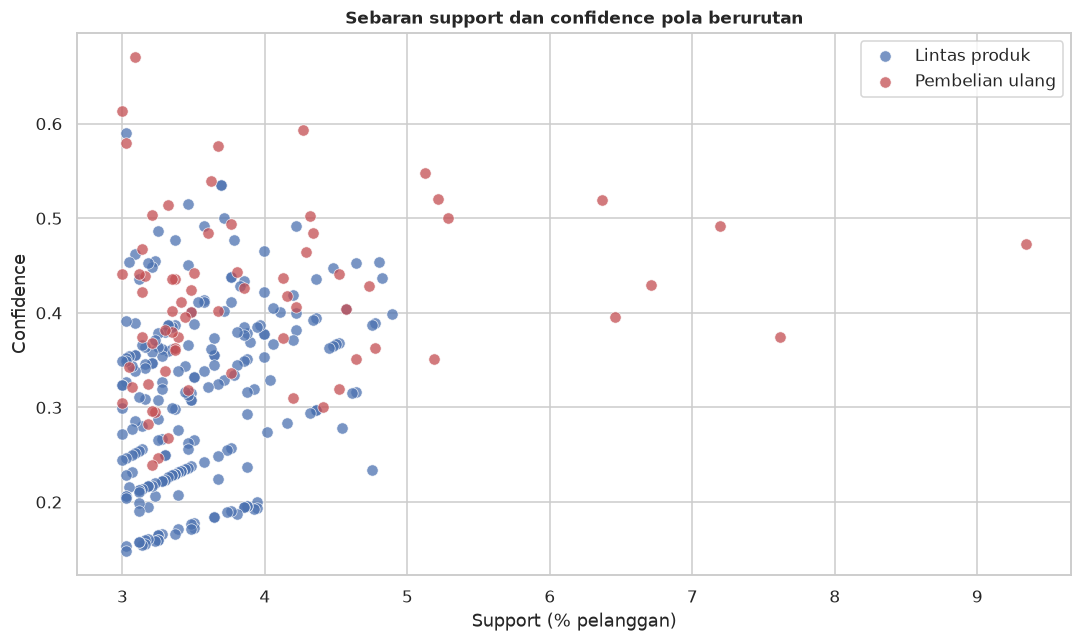

In [20]:
fig, ax = plt.subplots(figsize=(10, 6))
for label, color in [("Lintas produk", "#4c72b0"), ("Pembelian ulang", "#c44e52")]:
    subset = sequential[sequential["tipe"] == label]
    ax.scatter(subset["support_pct"], subset["confidence"], s=55, alpha=0.75, color=color, edgecolor="white", linewidth=0.5, label=label)
ax.set_title("Sebaran support dan confidence pola berurutan", fontsize=11, fontweight="bold")
ax.set_xlabel("Support (% pelanggan)")
ax.set_ylabel("Confidence")
ax.legend()
plt.tight_layout()
plt.savefig(cfg.OUTPUT_DIR / "support_confidence_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

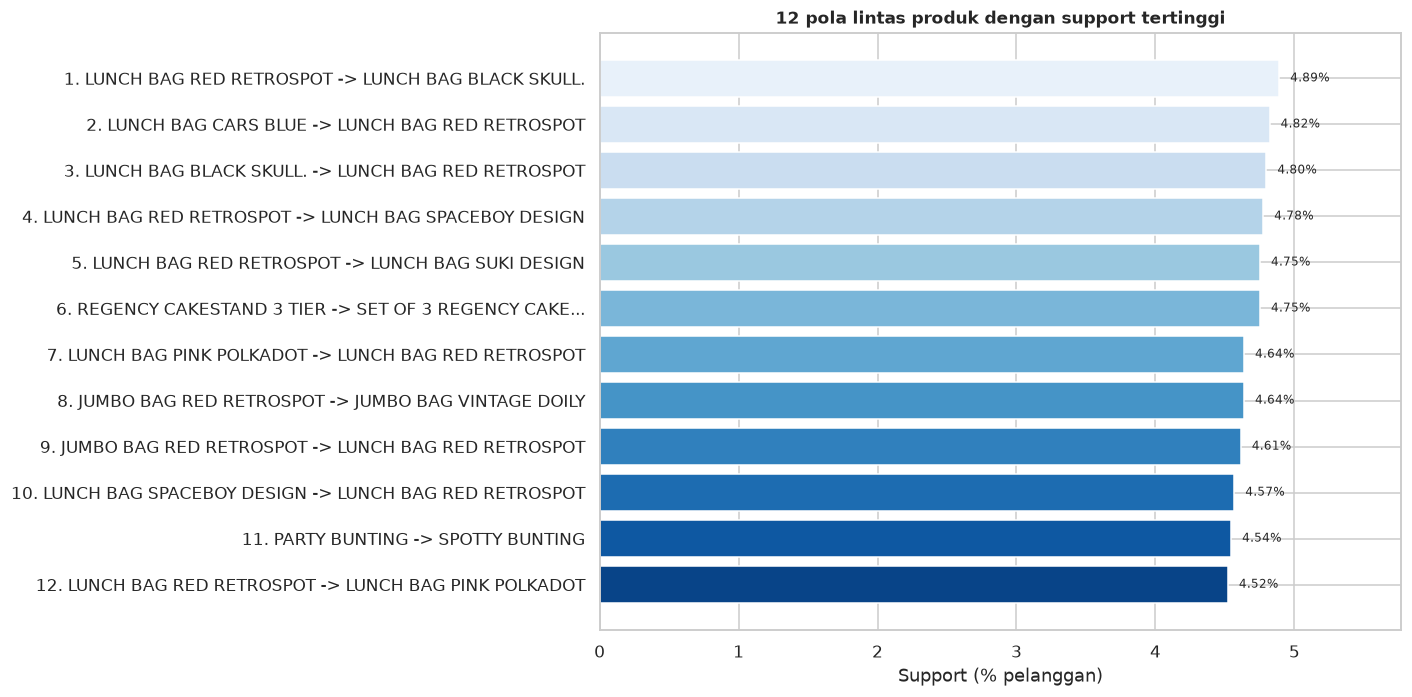

In [21]:
def short_label(text, max_len=52):
    return text if len(text) <= max_len else text[: max_len - 3] + "..."


top_distinct_plot = distinct.head(12).copy()
top_distinct_plot["label"] = [
    f"{rank}. {short_label(row.pola)}"
    for rank, (_, row) in enumerate(top_distinct_plot.iterrows(), start=1)
]
fig, ax = plt.subplots(figsize=(13, 6.5))
plot_df = top_distinct_plot.iloc[::-1]
bars = ax.barh(plot_df["label"], plot_df["support_pct"], color=sns.color_palette("Blues_r", len(plot_df)), edgecolor="white")
ax.set_title("12 pola lintas produk dengan support tertinggi", fontsize=11, fontweight="bold")
ax.set_xlabel("Support (% pelanggan)")
for bar, value in zip(bars, plot_df["support_pct"]):
    ax.text(value + 0.08, bar.get_y() + bar.get_height() / 2, f"{value:.2f}%", va="center", fontsize=8)
ax.set_xlim(0, plot_df["support_pct"].max() * 1.18)
plt.tight_layout()
plt.savefig(cfg.OUTPUT_DIR / "top_patterns_support.png", dpi=150, bbox_inches="tight")
plt.show()

## Implikasi Bisnis

Pola pembelian ulang dapat dipakai untuk program loyalitas, pengingat restock, dan penawaran paket isi ulang. Produk seperti lilin dekorasi, cake stand, dan jumbo bag memiliki peluang pembelian ulang yang cukup tinggi, sehingga pelanggan yang sudah membeli satu unit dapat ditawari diskon untuk pembelian kedua atau paket beberapa unit.

Pola lintas produk menunjukkan pelanggan cenderung mengoleksi beberapa desain dari keluarga produk yang sama. Lunch bag adalah contoh terkuat: pembeli satu desain memiliki peluang 40% sampai 45% membeli desain lain pada transaksi berikutnya. Rekomendasi yang dapat diterapkan adalah menampilkan seluruh varian dalam satu halaman produk, membuat bundling dua atau tiga desain, dan mengirim pengingat koleksi kepada pelanggan yang baru membeli satu desain. Pola serupa muncul pada jumbo bag dan set kue Regency.

Namun, support pola hanya 3% sampai 9% dari seluruh pelanggan. Pola ini sebaiknya diprioritaskan untuk pelanggan yang sudah memiliki item pertama, bukan untuk seluruh basis pelanggan. Dataset juga berasal dari satu pengecer UK pada 2010 sampai 2011, tidak memuat margin atau stok, dan 25% baris tanpa CustomerID tidak dapat dianalisis. Hubungan yang ditemukan adalah korelasi waktu, bukan bukti kausal, sehingga validasi dengan eksperimen A/B tetap diperlukan.

# Kesimpulan

Dataset Online Retail berhasil dibersihkan dari 541.909 baris dan 25.900 invoice menjadi 396.370 baris dan 18.405 invoice dengan 4.335 pelanggan. Sequence pembelian per pelanggan dibentuk dari 18.405 itemset invoice yang diurutkan berdasarkan waktu. PrefixSpan dengan minimum support 3% (130 pelanggan), kosakata 662 produk, dan panjang maksimum tiga langkah menghasilkan 964 pola, terdiri dari 662 pola satu langkah, 291 pola dua langkah, dan 11 pola tiga langkah.

Pola berurutan terkuat adalah pembelian ulang produk dekorasi populer: WHITE HANGING HEART T-LIGHT HOLDER (support 9,34%, confidence 0,473), REGENCY CAKESTAND 3 TIER (support 7,61%, confidence 0,375), dan JUMBO BAG RED RETROSPOT (support 7,20%, confidence 0,491). Pola lintas produk terkuat adalah kelompok lunch bag: LUNCH BAG RED RETROSPOT -> LUNCH BAG BLACK SKULL. (support 4,89%, confidence 0,398), LUNCH BAG CARS BLUE -> LUNCH BAG RED RETROSPOT (support 4,82%, confidence 0,436), dan LUNCH BAG BLACK SKULL. -> LUNCH BAG RED RETROSPOT (support 4,80%, confidence 0,454).

Secara keseluruhan, pelanggan Online Retail cenderung membeli ulang produk yang sama dan melanjutkan dengan varian desain dari keluarga produk yang sama. Peluang terbesar untuk rekomendasi terletak pada bundling varian lunch bag, jumbo bag, dan peralatan kue, bukan pada cross-sell antar kategori yang jauh berbeda.

## Saran Pengembangan

+ Menguji pola dengan minimum support lebih rendah setelah menggabungkan produk long tail ke dalam kategori, agar pola antar kategori tetap dapat ditemukan tanpa ledakan kombinasi.
+ Menambahkan batas waktu antar invoice, misalnya maksimum 90 hari, agar pola yang ditemukan lebih relevan untuk rekomendasi musiman.
+ Membandingkan PrefixSpan dengan GSP atau SPADE, serta menambahkan metrik lift dan conviction untuk mengukur kekuatan asosiasi berurutan.
+ Memisahkan pelanggan ritel dan grosir karena pola pembelian ulang pada pelanggan grosir dapat mendominasi hasil.
+ Memvalidasi rekomendasi dengan eksperimen A/B sebelum diterapkan pada sistem produksi.

# Penutup - File Output

Seluruh gambar, tabel, dan sequence disimpan di folder `output/` agar dapat dipakai langsung oleh laporan Typst/PDF. File utama adalah `patterns_final.csv` yang berisi seluruh 964 pola beserta support dan confidence.

In [22]:
for path in sorted(cfg.OUTPUT_DIR.glob("*")):
    print(f" - {path.name} ({path.stat().st_size / 1024:.1f} KB)")

 - cleaning_funnel.png (126.8 KB)
 - cleaning_summary.csv (0.4 KB)
 - customer_sequences.csv (11172.8 KB)
 - invoice_size_distribution.png (89.7 KB)
 - missing_values.png (40.8 KB)
 - parameter_sensitivity.csv (0.2 KB)
 - parameter_sensitivity.png (72.7 KB)
 - pattern_length_distribution.png (29.2 KB)
 - patterns_final.csv (62.2 KB)
 - sequence_length_distribution.png (85.6 KB)
 - support_confidence_scatter.png (115.3 KB)
 - top_distinct_patterns.csv (1.9 KB)
 - top_patterns.csv (2.0 KB)
 - top_patterns_support.png (171.4 KB)
 - top_products.csv (0.7 KB)
 - top_products.png (163.4 KB)
 - vocabulary_support.png (42.8 KB)
